<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h1 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 34px;
    ">
        Rice Variety Classification Using CNN (PyTorch)
    </h1>
</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Welcome! 👋
        <br>
        <br>
        Hello, everyone!
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Welcome to this project. Let's explore the data and uncover
        interesting insights together!
    </p>
</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Project Overview
</h3>

<p>
This project aims to develop a deep learning model for rice variety classification using image data. A Convolutional Neural Network (CNN) is implemented to identify five rice varieties through visual analysis.

The project follows a structured workflow, from data preparation and model development to training, experimentation, and performance evaluation, with a focus on understanding CNN architecture and improving classification performance.
</p>
</div>

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Why This Dataset?
</h3>

<p>
    The Rice Image Dataset was selected to investigate the effectiveness of deep learning in distinguishing visually similar rice varieties. The dataset contains 75,000 images belonging to five classes: Arborio, Basmati, Ipsala, Jasmine, and Karacadag.

The classification task requires the model to learn discriminative visual features, including grain shape, texture, and color. The dataset also provides sufficient samples to develop, train, and evaluate a multiclass image classification model.
</p>

<hr style="border: 0; border-top: 5px solid #D9AA55;">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Why Convolutional Neural Networks (CNNs)?
</h3>

<p>
    Convolutional Neural Networks (CNNs) were selected because they are specifically designed to process grid-structured data such as images.

Unlike traditional fully connected neural networks, CNNs use convolutional filters to learn spatial patterns while sharing parameters across different image regions.

In rice image classification, these filters can capture visual characteristics such as edges, grain shapes, and textures. As information passes through deeper layers, the network can learn increasingly complex representations that help distinguish between rice varieties.

Additionally, CNNs reduce the need for manual feature engineering by automatically learning relevant visual features directly from training images.

The objective of this project is to investigate how effectively a CNN can classify five rice varieties using PyTorch.
</p>

</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Importing libraries
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Importing the essential libraries for data processing,
        visualization, and deep learning.
    </p>
</div>


In [25]:
import warnings
warnings.filterwarnings('ignore')

# ==================== Standard Python Libraries ====================
import os
import random
from pathlib import Path
import hashlib
from itertools import combinations

# ==================== Data Manipulation & Numerical Computing ====================
import numpy as np
import pandas as pd

# ==================== Data Visualization ====================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.image import imread

# ==================== Image Processing ====================
from PIL import Image

# ==================== Utilities ====================
from collections import Counter, defaultdict
from tqdm.auto import tqdm

# ==================== Machine Learning - sklearn ====================
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

# ==================== Deep Learning - PyTorch ====================
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import random_split

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from torchinfo import summary

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [26]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Reading Data
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Loading the dataset for analysis
    </p>
</div>


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<p>
 At this stage, we make sure the dataset path is correct.
    
We see the names of the classes.  

We check the number of images in each class.  

If the path is wrong or a folder doesn't exist, we'll notice it before the next steps.
</p>
</div>

In [27]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/muratkokludataset
/kaggle/input/datasets/muratkokludataset/rice-image-dataset
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset/Arborio
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset/Basmati
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset/Ipsala
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset/Jasmine
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset/Karacadag


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<p>
 At this stage, ImageFolder identifies images and class labels and applies transformations when accessing each image.
</p>
</div>

In [28]:
data_dir = "/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset"

transform = transforms.Compose([transforms.Resize((250, 250)), transforms.ToTensor()])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)

counts = Counter(dataset.targets)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

for idx, class_name in enumerate(dataset.classes):
    print(f"{class_name}: {counts[idx]}")

Total images: 75000
Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
Class mapping: {'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}
Arborio: 15000
Basmati: 15000
Ipsala: 15000
Jasmine: 15000
Karacadag: 15000


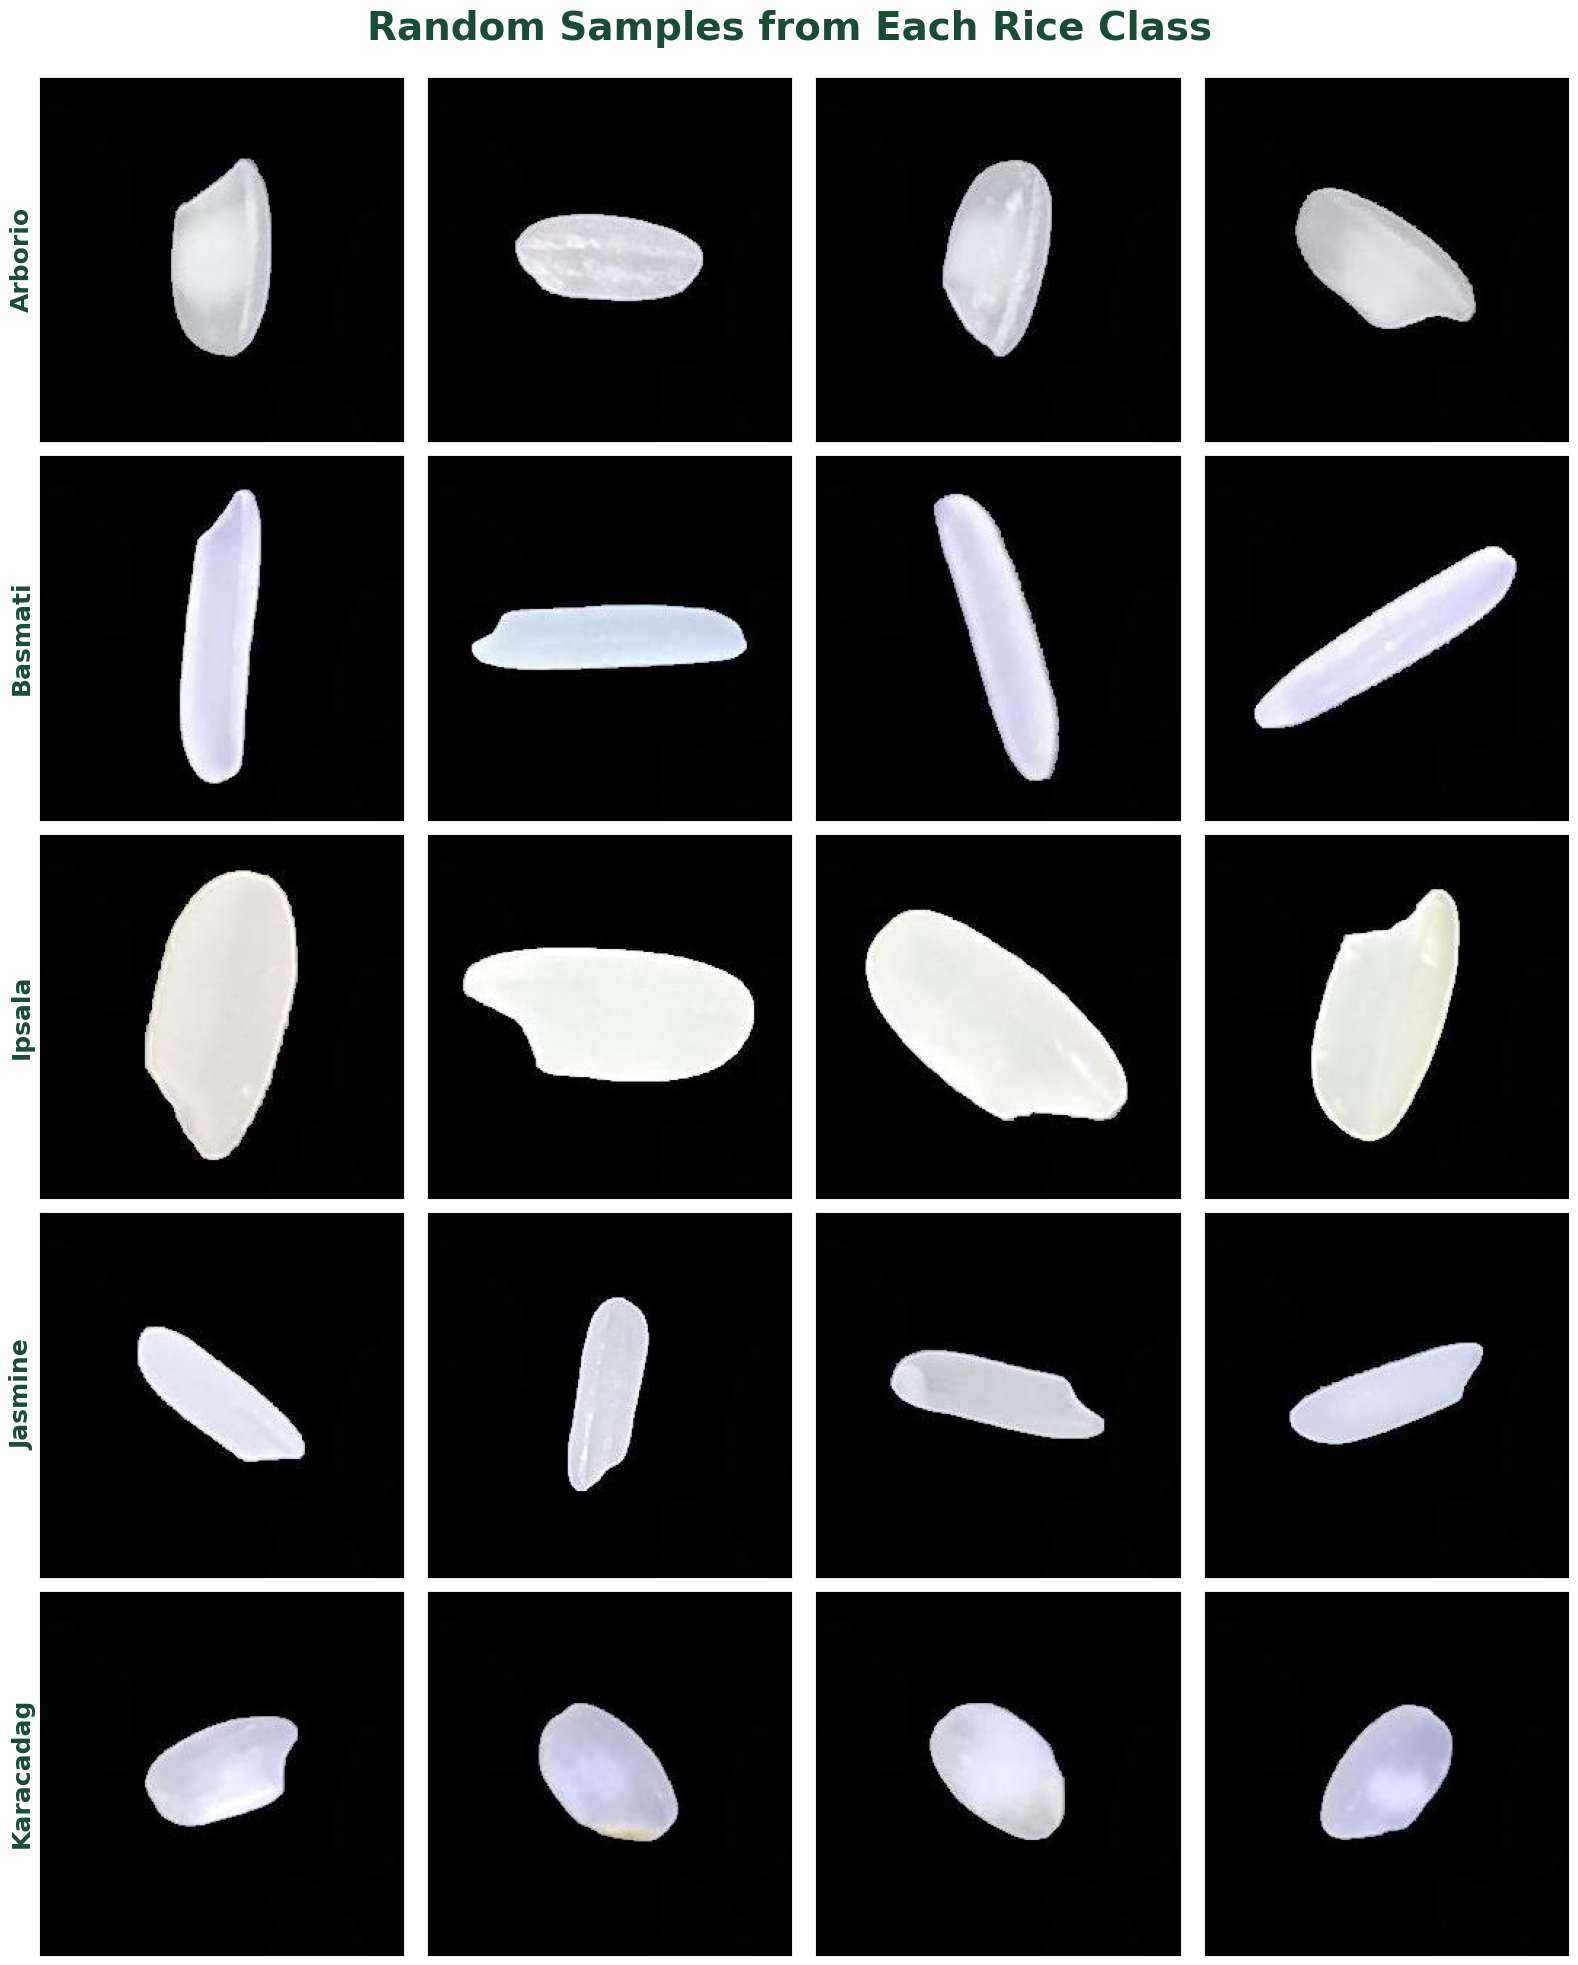

In [29]:
data_dir = Path(data_dir)
classes = dataset.classes

plt.figure(figsize=(16, 20))

for i, class_name in enumerate(classes):
    image_paths = list((data_dir / class_name).glob("*"))
    random_images = random.sample(image_paths, 4)

    for j, image_path in enumerate(random_images):
        plt.subplot(len(classes), 4, i * 4 + j + 1)

        img = imread(image_path)
        plt.imshow(img)

        plt.xticks([])
        plt.yticks([])

        if j == 0:
            plt.ylabel(class_name, fontsize=18, fontweight="bold", color="#174D35")

plt.suptitle("Random Samples from Each Rice Class", fontsize=28, fontweight="bold", y=0.98, color="#174D35")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [30]:
image_modes = Counter()

sampled_images = random.sample(
    dataset.samples,
    min(1000, len(dataset))
)

for image_path, _ in sampled_images:
    with Image.open(image_path) as img:
        image_modes[img.mode] += 1

for mode, count in image_modes.items():
    print(f"{mode}: {count} ({count / len(sampled_images) * 100:.2f}%)")

RGB: 1000 (100.00%)


Image Mode: RGB
Image Size: (250, 250)
Image Class: Arborio


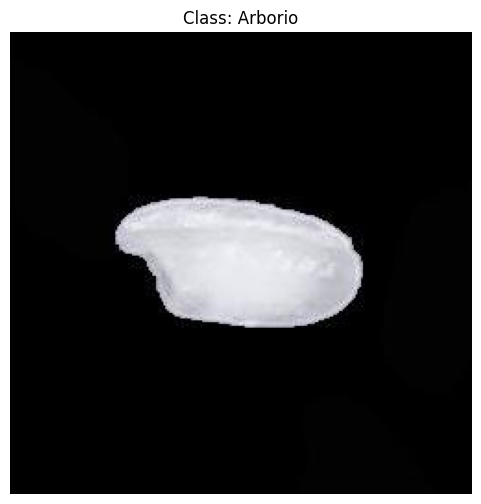

In [31]:
image_path, label = dataset.samples[0]

image = Image.open(image_path)

print("Image Mode:", image.mode)
print("Image Size:", image.size)
print("Image Class:", dataset.classes[label])

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(f"Class: {dataset.classes[label]}")
plt.axis("off")
plt.show()

In [32]:
sample_size = 500
sample_indices = np.random.default_rng(42).choice(len(dataset), size=sample_size, replace=False)

color_images = 0
grayscale_images = 0

for idx in sample_indices:
    image_path, _ = dataset.samples[idx]

    with Image.open(image_path) as image:
        image = np.array(image.convert("RGB"))

    if np.any(
        (image[:, :, 0] != image[:, :, 1]) |
        (image[:, :, 1] != image[:, :, 2])
    ):
        color_images += 1
    else:
        grayscale_images += 1

print(f"Sampled Images: {sample_size}")
print(f"Color Images: {color_images}")
print(f"Grayscale Images: {grayscale_images}")

Sampled Images: 500
Color Images: 500
Grayscale Images: 0


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Image Color Analysis
</h3>

<p>

All images are stored in RGB format. A random sample of 500 images
was examined by comparing their RGB channels.

All sampled images contained actual color information, confirming
that the dataset consists of color images rather than grayscale images.
</p>
</div>

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Duplicate Image Detection
</h3>

<p>

Before training the model, we check the dataset for duplicate and highly similar images. This helps prevent data leakage between training, validation, and test sets, ensuring a more reliable evaluation of model performance.
</p>
</div>

In [33]:
image_extensions = {".jpg", ".jpeg", ".png"}

image_paths = [
    path for path in data_dir.rglob("*")
    if path.suffix.lower() in image_extensions
]

hash_groups = defaultdict(list)

for image_path in tqdm(image_paths, desc="Calculating SHA-256"):

    file_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()

    hash_groups[file_hash].append(image_path)

Calculating SHA-256:   0%|          | 0/75000 [00:00<?, ?it/s]

In [34]:
duplicates = {
    file_hash: paths
    for file_hash, paths in hash_groups.items()
    if len(paths) > 1
}

duplicate_groups = len(duplicates)

duplicate_images = sum(
    len(paths) - 1
    for paths in duplicates.values()
)

total_images = sum(len(paths) for paths in hash_groups.values())

print(f"Total Images: {total_images:,}")
print(f"Duplicate Groups: {duplicate_groups:,}")
print(f"Duplicate Images: {duplicate_images:,}")

Total Images: 75,000
Duplicate Groups: 297
Duplicate Images: 297


In [35]:
duplicate_records = []

for group_id, (file_hash, paths) in enumerate(duplicates.items(), start=1):

    for image_path in paths:
        duplicate_records.append({
            "group_id": group_id,
            "file_name": image_path.name,
            "class": image_path.parent.name,
            "path": str(image_path),
            "hash": file_hash
        })

duplicates_df = pd.DataFrame(duplicate_records)

duplicates_df.head(20)

,group_id,file_name,class,path,hash
0,1,Ipsala (1870).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,e90896c6362910f198e1cca7a42acf98fb58c34874df03...
1,1,Ipsala (1969).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,e90896c6362910f198e1cca7a42acf98fb58c34874df03...
2,2,Ipsala (1871).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,50115d32bc8307910e0654fbc0c0d634e2b1a542fd9d18...
3,2,Ipsala (1973).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,50115d32bc8307910e0654fbc0c0d634e2b1a542fd9d18...
4,3,Ipsala (1874).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,a0b4402eccc80a694ea0b03b95df11dc7ef210e6c24a18...
5,3,Ipsala (1974).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,a0b4402eccc80a694ea0b03b95df11dc7ef210e6c24a18...
6,4,Ipsala (1875).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,74c04e6cac54a1f1d64deab0ab5e1b4aba43fcafc98c74...
7,4,Ipsala (1975).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,74c04e6cac54a1f1d64deab0ab5e1b4aba43fcafc98c74...
8,5,Ipsala (1876).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,a1707f535872ab3ac403390488b5e49b82f456e1210d1a...
9,5,Ipsala (1976).jpg,Ipsala,/kaggle/input/datasets/muratkokludataset/rice-...,a1707f535872ab3ac403390488b5e49b82f456e1210d1a...


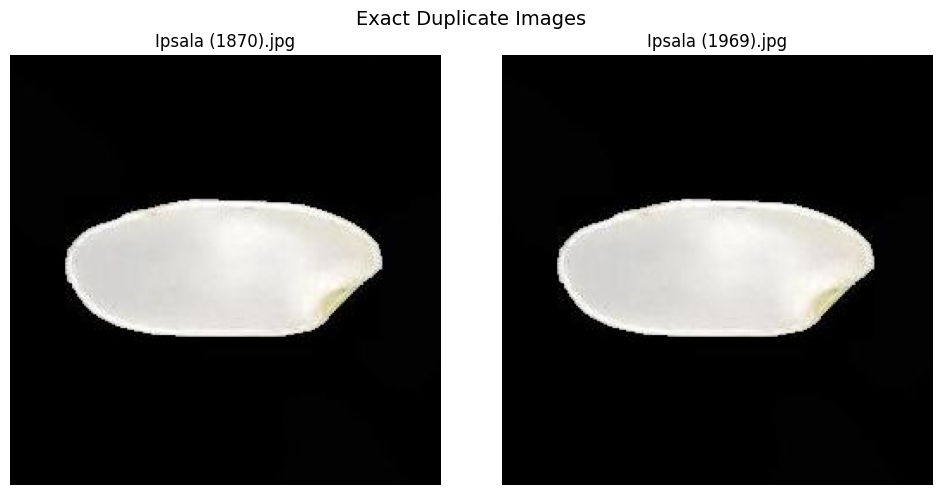

In [36]:
sample_group = next(iter(duplicates.values()))

# Load images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, image_path in zip(axes, sample_group[:2]):
    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.suptitle("Exact Duplicate Images", fontsize=14)
plt.tight_layout()
plt.show()

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<p>
 Next Step Splitting the Dataset
    
Since we have 75,000 images, we'll keep the split at a 70/15/15 ratio:

- Train: To learn the model's weights
  
- Validation: To evaluate the model during training and select settings
  
- Test: For the final evaluation of the model on data that wasn't used in previous stages
</p>
</div>

In [37]:
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator,
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 52500
Validation: 11250
Test: 11250


In [38]:
images, labels = train_dataset[0]
print(images.shape)
print(labels)

torch.Size([3, 250, 250])
2


In [39]:
images, labels = test_dataset[0]
print(images.shape)
print(labels)

torch.Size([3, 250, 250])
3


In [40]:
images, labels = val_dataset[0]
print(images.shape)
print(labels)

torch.Size([3, 250, 250])
4


In [41]:
batch_size = 32

In [42]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

In [43]:
images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

torch.Size([32, 3, 250, 250])
torch.Size([32])


<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Device of Process
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        <!-- Building and training the CNN model -->
        CNN Architecture Design and Experimentation
    </p>
</div>

In [44]:
# for moving data into GPU (if available)
def get_default_device():
    """Pick GPU if available, else CPU"""
    if torch.cuda.is_available():
        return torch.device("cuda")
    else:
        return torch.device("cpu")

In [45]:
# for moving data to device (CPU or GPU)
def to_device(data, device):
    """Move tensor(s) to chosen device"""
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

In [46]:
# for loading in the device (GPU if available else CPU)
class DeviceDataLoader():
    """Wrap a dataloader to move data to a device"""
    def __init__(self, dataloader, device):
        self.dataloader = dataloader
        self.device = device
        
    def __iter__(self):
        """Yield a batch of data after moving it to device"""
        for b in self.dataloader:
            yield to_device(b, self.device)
        
    def __len__(self):
        """Number of batches"""
        return len(self.dataloader)

In [47]:
device = get_default_device()
device

device(type='cuda')

In [48]:
# Moving data into GPU, WrappedDataLoader
train_dataloader = DeviceDataLoader(train_loader, device)
valid_dataloader = DeviceDataLoader(val_loader, device)

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Model
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        <!-- Building and training the CNN model -->
        CNN Architecture Design and Experimentation
    </p>
</div>

In [49]:
# for calculating the accuracy
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

In [50]:
class ImageClassificationBase(nn.Module):

    def training_step(self, batch):
        images, labels = batch

        outputs = self(images)
        loss = F.cross_entropy(outputs, labels)

        correct = (outputs.argmax(dim=1) == labels).sum()

        return loss, correct

    def validation_step(self, batch):
        images, labels = batch

        outputs = self(images)
        loss = F.cross_entropy(outputs, labels)

        correct = (outputs.argmax(dim=1) == labels).sum()

        return {
            "val_loss": loss.detach(),
            "correct": correct.detach(),
            "batch_size": len(labels),
        }

    def validation_epoch_end(self, outputs):

        total_samples = sum(x["batch_size"] for x in outputs)

        epoch_loss = sum(x["val_loss"] * x["batch_size"] for x in outputs) / total_samples

        total_correct = sum(x["correct"] for x in outputs)

        epoch_acc = total_correct / total_samples

        return {
            "val_loss": epoch_loss.item(),
            "val_acc": epoch_acc.item(),
        }

    def epoch_end(self, epoch, result):

        print(
            f"Epoch [{epoch + 1}], "
            f"train_loss: {result['train_loss']:.4f}, "
            f"train_acc: {result['train_acc']:.4f}, "
            f"val_loss: {result['val_loss']:.4f}, "
            f"val_acc: {result['val_acc']:.4f}"
        )

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    RiceNet-Inspired Architecture
</h3>

<p>

Due to the high visual similarity between rice varieties, we used a GoogLeNet-inspired architecture with Inception modules. By applying parallel convolutional branches with different kernel sizes, the model can capture subtle visual details, patterns, and variations from multiple perspectives, helping it learn more discriminative features and distinguish between visually similar rice varieties.
</p>
</div>

In [51]:
def InceptionBlock(in_channels, ch1x1, ch3x3_reduce, ch3x3,
                   ch5x5_reduce, ch5x5, pool_proj, momentum=0.1):

    return nn.ModuleDict({

        'branch1': nn.Sequential(
            nn.Conv2d(in_channels, ch1x1, kernel_size=1),
            nn.BatchNorm2d(ch1x1, momentum=momentum),
            nn.ReLU()
        ),

        'branch2': nn.Sequential(
            nn.Conv2d(in_channels, ch3x3_reduce, kernel_size=1),
            nn.BatchNorm2d(ch3x3_reduce, momentum=momentum),
            nn.ReLU(),
            nn.Conv2d(ch3x3_reduce, ch3x3, kernel_size=3, padding=1),
            nn.BatchNorm2d(ch3x3, momentum=momentum),
            nn.ReLU()
        ),

        'branch3': nn.Sequential(
            nn.Conv2d(in_channels, ch5x5_reduce, kernel_size=1),
            nn.BatchNorm2d(ch5x5_reduce, momentum=momentum),
            nn.ReLU(),
            nn.Conv2d(ch5x5_reduce, ch5x5, kernel_size=5, padding=2),
            nn.BatchNorm2d(ch5x5, momentum=momentum),
            nn.ReLU()
        ),

        'branch4': nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, pool_proj, kernel_size=1),
            nn.BatchNorm2d(pool_proj, momentum=momentum),
            nn.ReLU()
        )
    })

In [52]:
class Inception(nn.Module):

    def __init__(self, in_channels, ch1x1, ch3x3_reduce, ch3x3,
                 ch5x5_reduce, ch5x5, pool_proj, momentum=0.1):

        super().__init__()

        self.block = InceptionBlock(in_channels, ch1x1, ch3x3_reduce, ch3x3, ch5x5_reduce, ch5x5, pool_proj, momentum)

    def forward(self, x):

        outputs = [branch(x) for branch in self.block.values()]

        return torch.cat(outputs, dim=1)

In [53]:
class RiceNet(ImageClassificationBase):

    def __init__(self, num_classes=5, momentum=0.9):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32, momentum=momentum),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            Inception(32, 16, 16, 24, 8, 16, 8, momentum),

            nn.MaxPool2d(kernel_size=2, stride=2),

            Inception(64, 32, 32, 48, 16, 24, 16, momentum),

            nn.MaxPool2d(kernel_size=2, stride=2),

            Inception(120, 48, 32, 64, 16, 32, 24, momentum)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(168, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [54]:
model = RiceNet(num_classes=5)

x = torch.randn(1, 3, 224, 224)

print(model(x).shape)

torch.Size([1, 5])


In [55]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RiceNet(num_classes=len(dataset.classes), momentum=0.9).to(device)

print("Device:", device)

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: cuda
Trainable parameters: 86613


In [56]:
summary(model)

Layer (type:depth-idx)                        Param #
RiceNet                                       --
├─Sequential: 1-1                             --
│    └─Conv2d: 2-1                            896
│    └─BatchNorm2d: 2-2                       64
│    └─ReLU: 2-3                              --
│    └─MaxPool2d: 2-4                         --
│    └─Inception: 2-5                         --
│    │    └─ModuleDict: 3-1                   8,456
│    └─MaxPool2d: 2-6                         --
│    └─Inception: 2-7                         --
│    │    └─ModuleDict: 3-2                   30,072
│    └─MaxPool2d: 2-8                         --
│    └─Inception: 2-9                         --
│    │    └─ModuleDict: 3-3                   46,280
├─Sequential: 1-2                             --
│    └─AdaptiveAvgPool2d: 2-10                --
│    └─Flatten: 2-11                          --
│    └─Dropout: 2-12                          --
│    └─Linear: 2-13                           845
To

In [57]:
@torch.no_grad()
def evaluate(model, val_loader, device):

    model.eval()

    outputs = []

    for images, labels in val_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        result = model.validation_step((images, labels))

        outputs.append(result)

    return model.validation_epoch_end(outputs)

In [58]:
def get_lr(optimizer):
    return optimizer.param_groups[0]["lr"]

In [59]:
def fit_one_cycle(epochs, max_lr, model, train_loader, val_loader, device, weight_decay=1e-4, grad_clip=0.15):

    history = []

    optimizer = torch.optim.Adam(model.parameters(), lr=max_lr, weight_decay=weight_decay)

    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr, epochs=epochs, steps_per_epoch=len(train_loader))

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0
        learning_rates = []

        progress_bar = tqdm(train_loader, desc=f"Epoch [{epoch + 1}/{epochs}]")

        for images, labels in progress_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            loss, correct = model.training_step((images, labels))

            loss.backward()

            if grad_clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)

            optimizer.step()
            scheduler.step()

            batch_size = len(labels)

            total_loss += loss.detach().item() * batch_size
            total_correct += correct.detach().item()
            total_samples += batch_size

            learning_rates.append(get_lr(optimizer))

            progress_bar.set_postfix(loss=f"{loss.item():.4f}")

        result = evaluate(model, val_loader, device)

        result["train_loss"] = total_loss / total_samples
        result["train_acc"] = total_correct / total_samples
        result["lrs"] = learning_rates

        model.epoch_end(epoch, result)

        history.append(result)

    return history

In [60]:
print("GPU:", torch.cuda.get_device_name(0))
print("Train samples:", len(train_loader.dataset))
print("Train batches:", len(train_loader))
print("Batch size:", train_loader.batch_size)
print("Workers:", train_loader.num_workers)

GPU: Tesla T4
Train samples: 52500
Train batches: 1641
Batch size: 32
Workers: 4


In [61]:
num_epochs = 20
learning_rate = 0.001
weight_decay = 0.0001
grad_clip = 0.15

In [62]:
%%time
model_history= fit_one_cycle(epochs=num_epochs, max_lr=learning_rate, model=model, train_loader=train_loader, val_loader=val_loader,
                        device=device, weight_decay=weight_decay, grad_clip=grad_clip)

Epoch [1/20]:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch [1], train_loss: 0.8653, train_acc: 0.7765, val_loss: 0.4845, val_acc: 0.9179


Epoch [2/20]:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch [2], train_loss: 0.3475, train_acc: 0.9287, val_loss: 0.4417, val_acc: 0.8534


Epoch [3/20]:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch [3], train_loss: 0.1902, train_acc: 0.9540, val_loss: 0.2257, val_acc: 0.9242


... (30 outputs left out)

Epoch [19/20]:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch [19], train_loss: 0.0088, train_acc: 0.9978, val_loss: 0.0097, val_acc: 0.9972


Epoch [20/20]:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch [20], train_loss: 0.0089, train_acc: 0.9974, val_loss: 0.0065, val_acc: 0.9979
CPU times: user 1h 11min 5s, sys: 5min 25s, total: 1h 16min 30s
Wall time: 1h 20min 34s


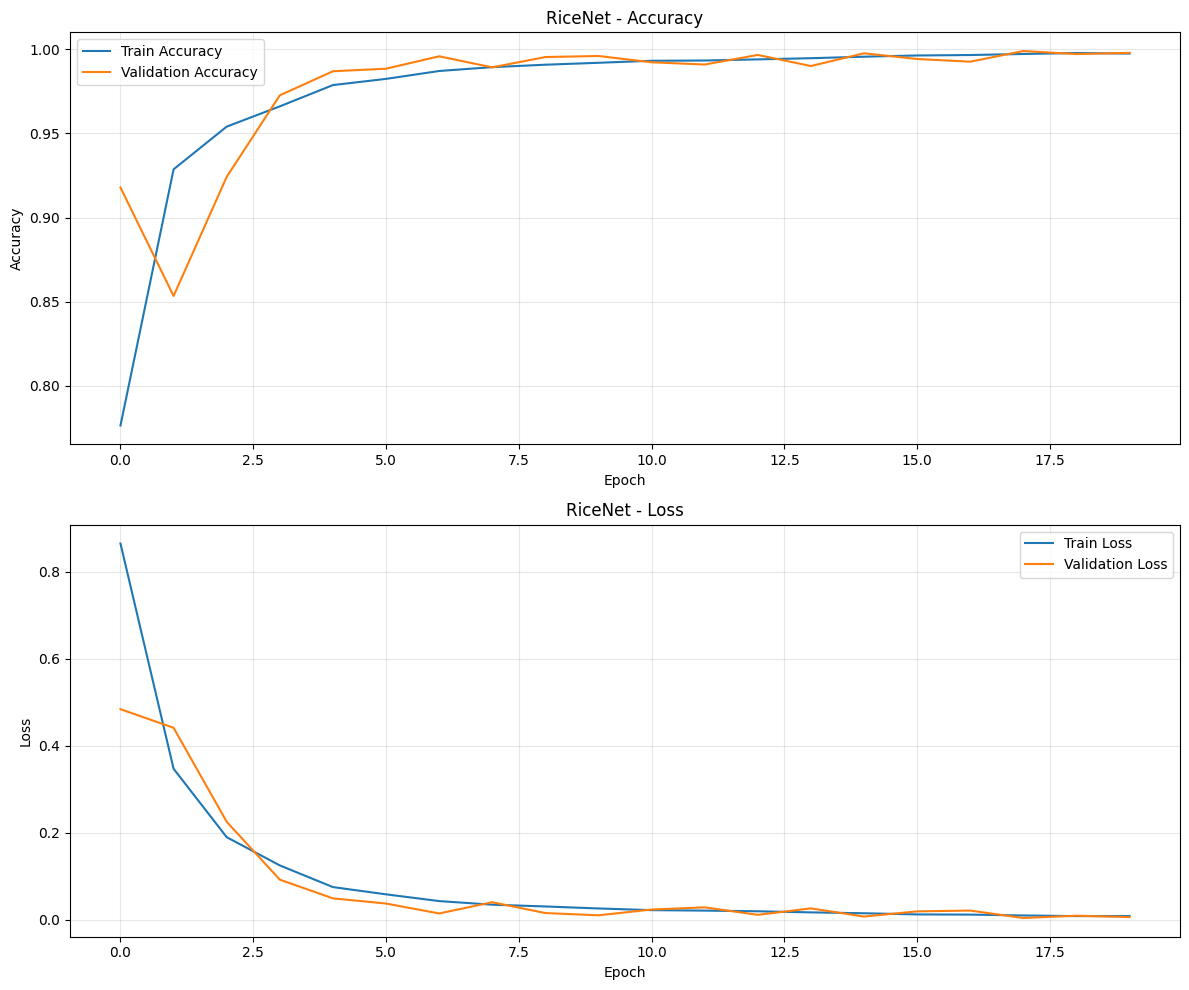

In [70]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# ==================== Accuracy ====================
axes[0].plot([x['train_acc'] for x in model_history], label='Train Accuracy')

axes[0].plot([x['val_acc'] for x in model_history], label='Validation Accuracy')

axes[0].set_title('RiceNet - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)


# ==================== Loss ====================
axes[1].plot([x['train_loss'] for x in model_history], label='Train Loss')

axes[1].plot([x['val_loss'] for x in model_history], label='Validation Loss')

axes[1].set_title('RiceNet - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
def evaluate_test(model, test_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = torch.nn.functional.cross_entropy(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    test_loss = total_loss / total_samples
    test_accuracy = accuracy_score(all_labels, all_predictions)

    print(f"Test Loss     : {test_loss:.4f}")
    print(f"Test Accuracy : {test_accuracy:.4%}")

    return all_labels, all_predictions

In [65]:
y_true, y_pred = evaluate_test(model=model, test_loader=test_loader, device=device)

Testing:   0%|          | 0/352 [00:00<?, ?it/s]

Test Loss     : 0.0085
Test Accuracy : 99.7156%


In [66]:
print(classification_report(y_true, y_pred, target_names=dataset.classes, digits=4, zero_division=0))

              precision    recall  f1-score   support

     Arborio     0.9969    0.9952    0.9961      2288
     Basmati     0.9996    0.9942    0.9969      2244
      Ipsala     1.0000    1.0000    1.0000      2225
     Jasmine     0.9933    0.9973    0.9953      2231
   Karacadag     0.9960    0.9991    0.9976      2262

    accuracy                         0.9972     11250
   macro avg     0.9972    0.9972    0.9972     11250
weighted avg     0.9972    0.9972    0.9972     11250



In [67]:
error_data = pd.DataFrame({
    "Actual": [dataset.classes[i] for i in y_true],
    "Predicted": [dataset.classes[i] for i in y_pred]
})

errors = error_data[error_data["Actual"] != error_data["Predicted"]]

error_summary = pd.crosstab(errors["Actual"], errors["Predicted"])

print(error_summary)

Predicted  Arborio  Basmati  Jasmine  Karacadag
Actual                                         
Arborio          0        0       11          0
Basmati          1        0        4          8
Jasmine          4        1        0          1
Karacadag        2        0        0          0


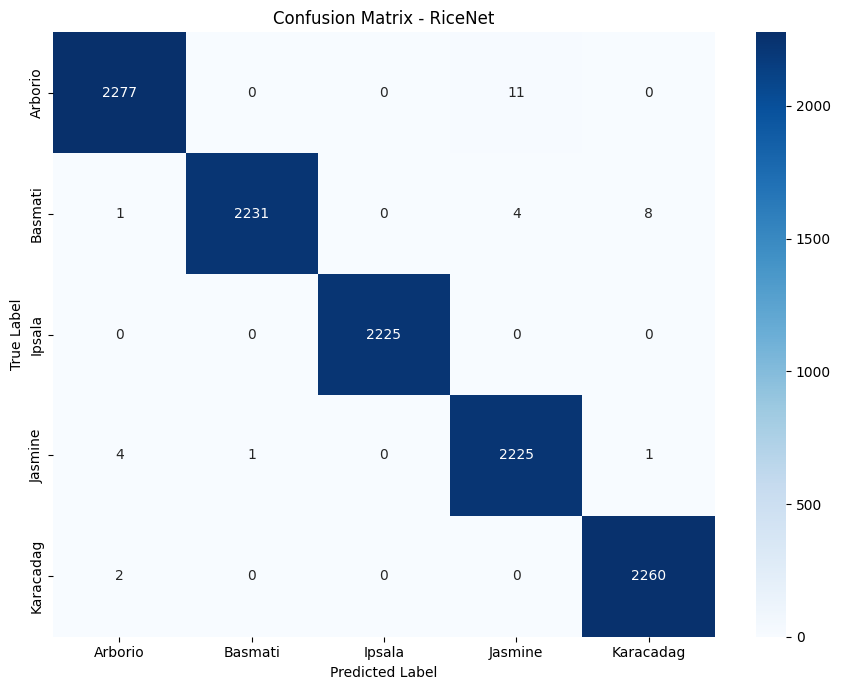

In [68]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - RiceNet")
plt.tight_layout()
plt.show()

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    padding: 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
">

<h3 style="color: #174D35; margin-top: 0; font-weight: bold;">
    Observation
</h3>

<p>

The model achieved an excellent test accuracy of **99.72%** with a very low test loss of **0.0085**, indicating strong classification performance on the unseen test dataset.
</p>
</div>

<div style="
    max-width: 1350px;
    background-color: #F4F0DF;
    font-family: 'vazir';
    padding: 20px 22px;
    border-left: 5px solid #D9AA55;
    border-radius: 8px;
    color: #26332B;
    text-align: center;
">
    <h5 style="
        color: #174D35;
        text-align: center;
        font-weight: bold;
        margin: 0;
        font-size: 24px;
    ">
        Thank You :)
    </h5>
    <p style="
        color: #387653;
        text-align: center;
        margin: 8px 0 0 0;
        font-size: 14px;
    ">
        Thank you for taking the time to explore this project.
        <br>
        See you in the next project!
    </p>
</div>
